# DATA 620 — Network Analysis of AI-Enabled Cyberattacks

**Andre Thomson**

## Approach

I started with a simple question: which Fortune 500 companies are being attacked by people using AI? My DATA 607 side project showed that public incident data can't answer that. Of 843 AI-enabled attack incidents, none named a Fortune 500 company as the victim. Victims of these attacks are usually not named.

So for this notebook I built networks from what the data *does* record well:

1. A **two-mode network** linking named AI products (ChatGPT, Claude, Gemini, ...) to attack types.
2. A **one-mode projection** of that network onto the AI products.
3. A **co-occurrence network** of MITRE ATLAS techniques, where two techniques are linked when they are tagged on the same incident.

The data is the GenAI & Agentic AI Security Incidents dataset (v2.13.0, CC BY 4.0) and MITRE ATLAS 2026.09, the ATLAS release the dataset says it maps to. `code/prepare_data.py` downloads both and builds the two CSV files this notebook reads.

## 1. Packages

I used NetworkX for the networks, pandas for the tables, and Matplotlib for the graphs.

In [1]:
import itertools
import networkx as nx
import pandas as pd
import matplotlib.pyplot as plt
from networkx.algorithms import bipartite

pd.set_option("display.max_rows", 40)
pd.set_option("display.width", 120)

## 2. Load the data

Each row is one AI-enabled attack incident. I kept incidents that describe AI being used **and** describe an intrusion or fraud, and I dropped CVE records (software bugs in AI products, not attacks).

In [2]:
incidents = pd.read_csv("data/ai_attack_incidents.csv", keep_default_na=False)
atlas = pd.read_csv("data/atlas_2026_09_techniques.csv")
atlas_name = dict(zip(atlas.technique_id, atlas.name))

print("AI-enabled attack incidents:", len(incidents))
print("Incidents naming an AI product:", (incidents.named_ai_tools != "").sum())
print("Incidents with ATLAS tags:", (incidents.atlas_techniques != "").sum())
print()
print(incidents.incident_type.value_counts().to_string())

assert len(incidents) == 843
assert incidents.id.is_unique

AI-enabled attack incidents: 843
Incidents naming an AI product: 134
Incidents with ATLAS tags: 821

incident_type
fraud/impersonation    457
intrusion              386


## 3. Why there is no victim network

My first idea was a two-mode network of AI tools and the companies they attacked. The `affected` field in the source data can't support that. In many rows it lists the attackers or the AI developers instead of the victims, and the companies in large campaigns are left unnamed. For example, the GTG-1002 espionage case (INC-02426) reportedly targeted about 30 organizations, but none of them are named.

So the node sets I use are things the data records consistently: the AI product named in the incident, the attack type, and the ATLAS techniques.

## 4. Two-mode network: AI products and attack types

A named AI product can show up in an incident for two very different reasons:

- **AI used as weapon**: the attacker used it, for example to make a deepfake or write phishing emails.
- **AI product attacked**: the product itself was the target, for example a prompt injection that leaks data out of an AI assistant.

I labelled each attack type with one of those roles. Deepfake, phishing, malware and misinformation count as weapon. Prompt injection, data exfiltration, jailbreak, poisoning, tool abuse and similar count as attacked. "other" stays unclear. Because the role comes from the attack type, every edge in this network has exactly one role.

In [3]:
named = incidents[incidents.named_ai_tools != ""].copy()
named["tool"] = named.named_ai_tools.str.split(";")
links = named.explode("tool").reset_index(drop=True)

print("Incidents naming at least one AI product:", len(named))
print("Incident-to-product links (an incident can name two products):", len(links))
role_table = pd.crosstab(links.tool, links.ai_role, margins=True, margins_name="Total")
role_table

Incidents naming at least one AI product: 134
Incident-to-product links (an incident can name two products): 147


ai_role,AI product attacked,AI used as weapon,unclear,Total
tool,,,,
ChatGPT/OpenAI,35,14,10,59
Claude,27,3,5,35
Copilot,11,2,0,13
Cursor,2,0,1,3
Dark-web LLMs,3,1,0,4
DeepSeek,2,0,1,3
Gemini,15,3,2,20
Image generators,1,0,0,1
Llama/Meta AI,3,1,1,5


In [4]:
edges = (links.groupby(["tool", "attack_vector", "ai_role"]).size()
              .reset_index(name="incidents"))

B = nx.Graph()
B.add_nodes_from(edges.tool.unique(), bipartite=0)
B.add_nodes_from(edges.attack_vector.unique(), bipartite=1)
for r in edges.itertuples():
    B.add_edge(r.tool, r.attack_vector, weight=r.incidents, role=r.ai_role)

tools = sorted(n for n, d in B.nodes(data=True) if d["bipartite"] == 0)
attack_types = sorted(n for n, d in B.nodes(data=True) if d["bipartite"] == 1)

print("AI products:", len(tools))
print("Attack types:", len(attack_types))
print("Edges:", B.number_of_edges())
print("Bipartite:", bipartite.is_bipartite(B))
print("Connected components:", nx.number_connected_components(B))
print("Isolates:", list(nx.isolates(B)))

assert bipartite.is_bipartite(B)
assert sum(w for _, _, w in B.edges(data="weight")) == len(links)

AI products: 12
Attack types: 18
Edges: 59
Bipartite: True
Connected components: 1
Isolates: []


In the graph below, AI products are on the left and attack types on the right. Thicker lines mean more incidents. Red lines are attacks *on* the AI product, blue lines are AI used *as a weapon*, and grey lines are unclear.

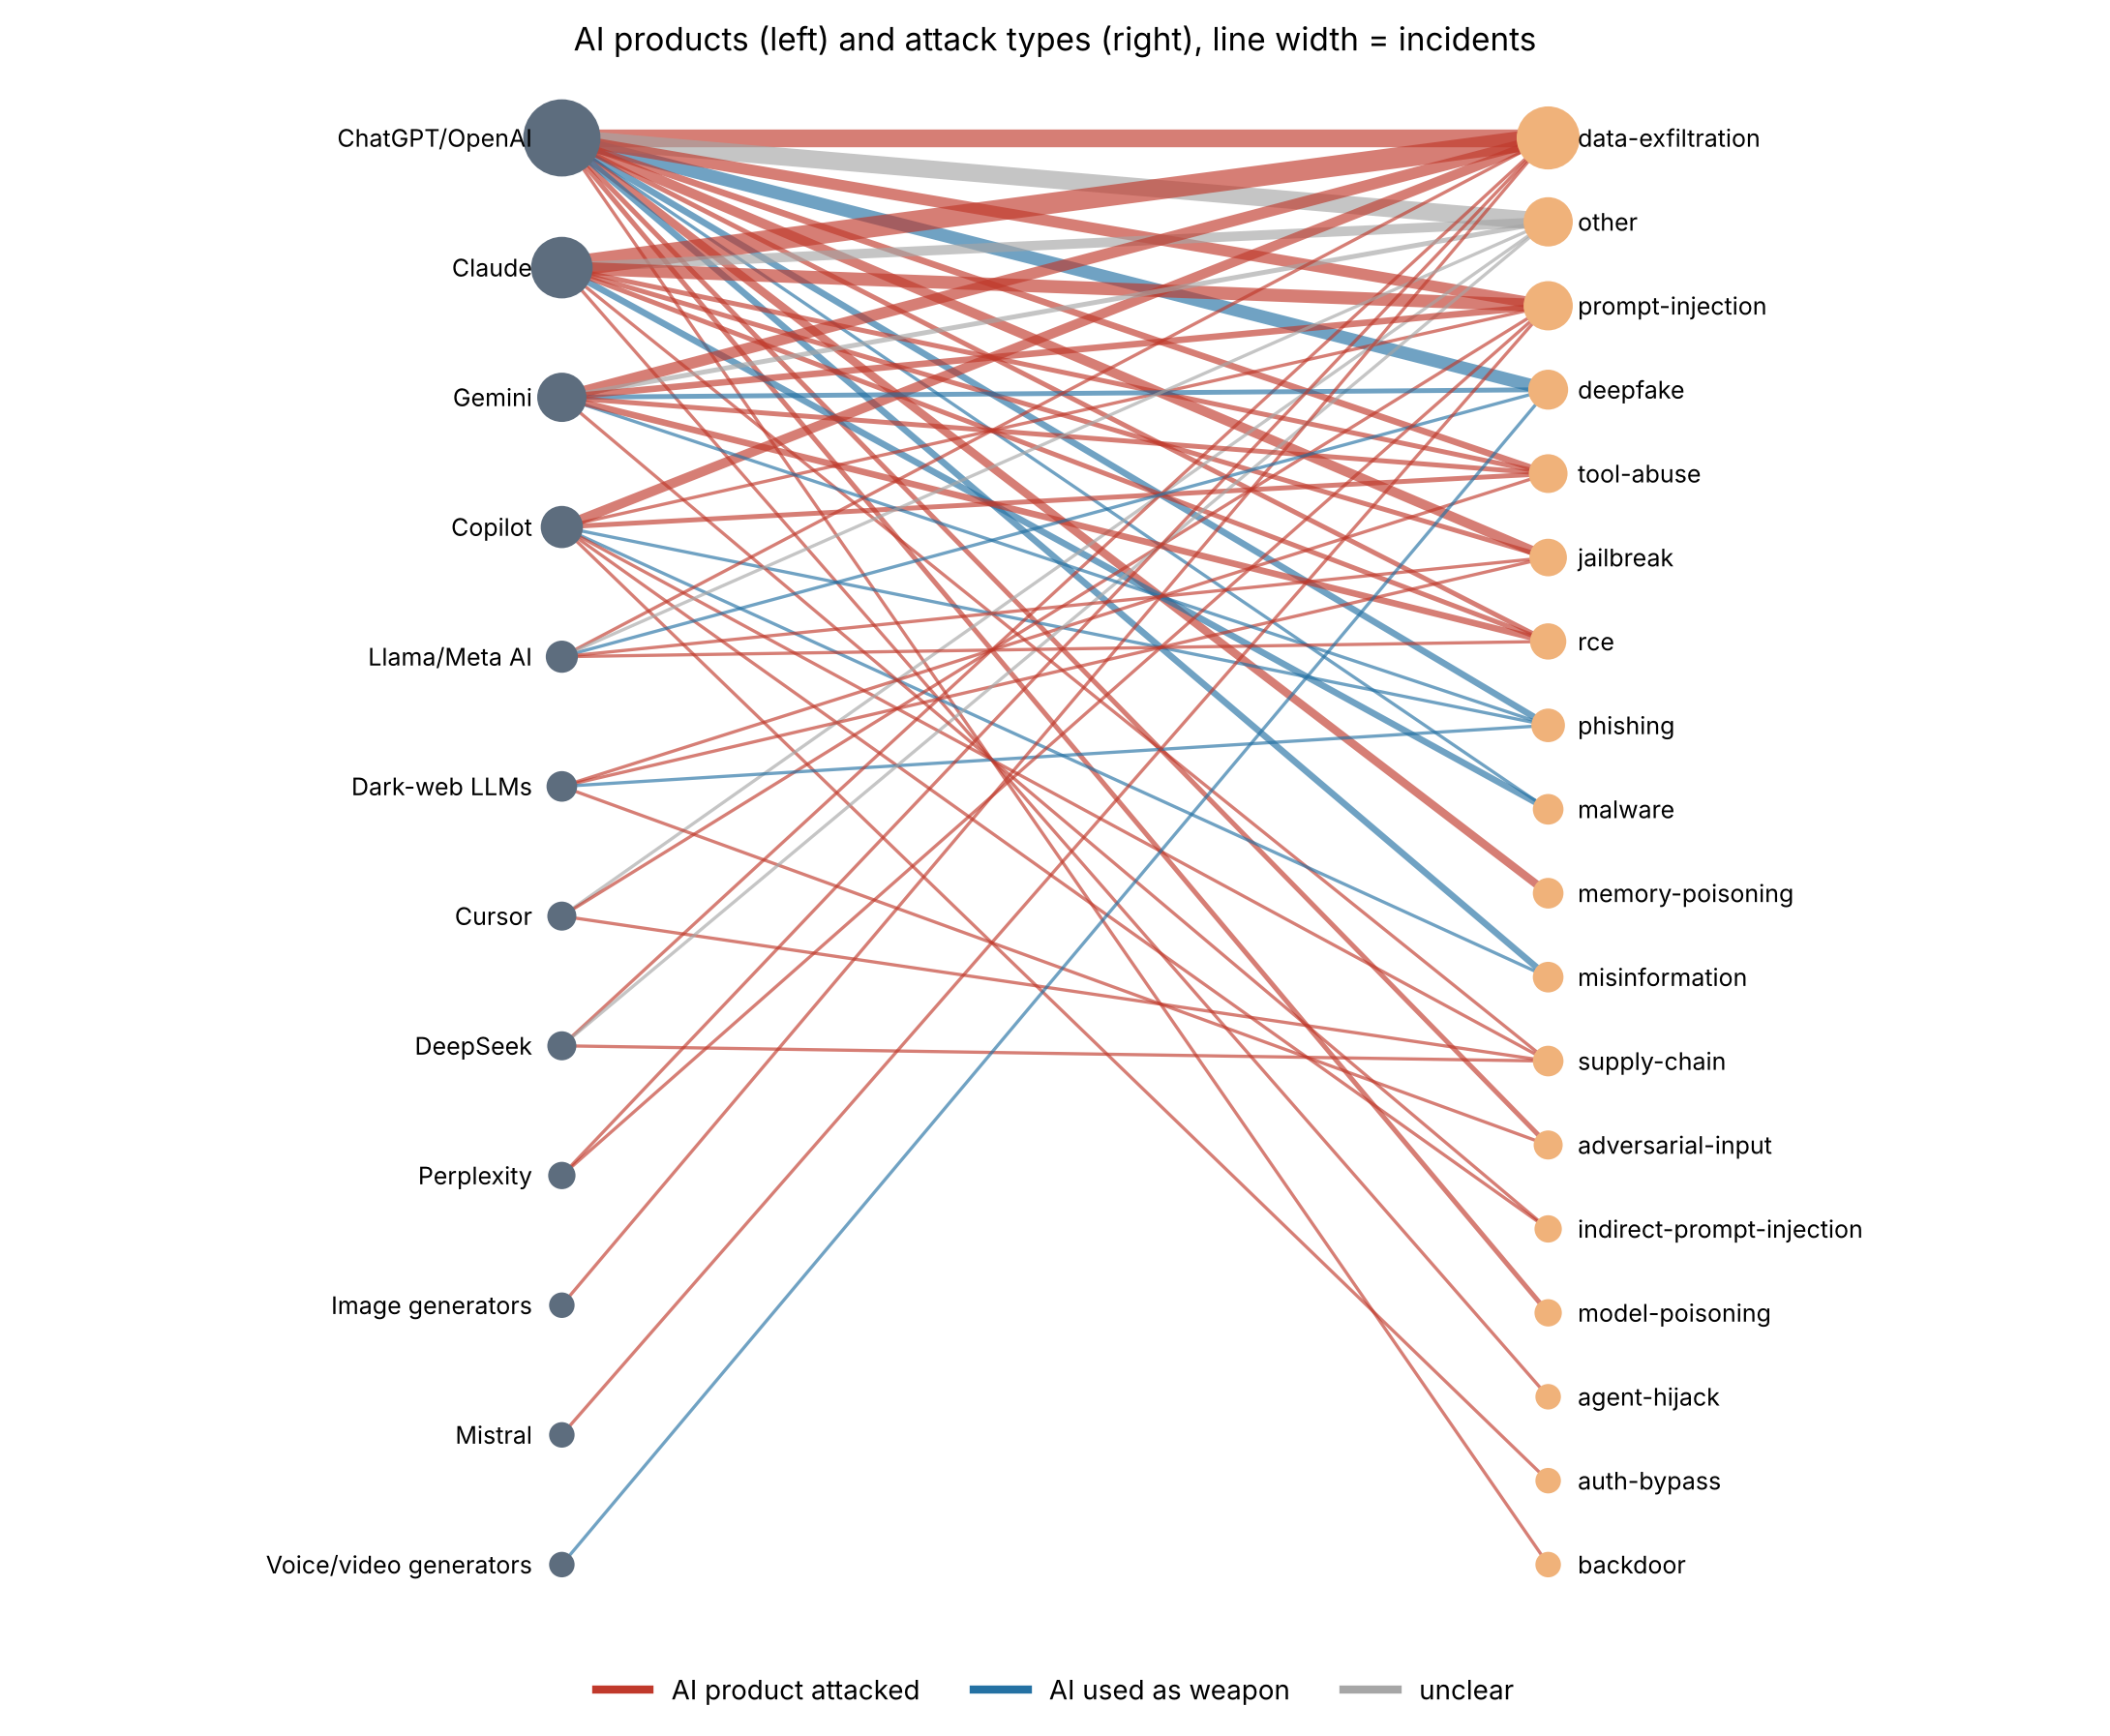

In [5]:
role_color = {"AI product attacked": "#c0392b", "AI used as weapon": "#2471a3", "unclear": "#a6a6a6"}

def column(nodes, x):
    order = sorted(nodes, key=lambda n: -B.degree(n, weight="weight"))
    step = 1 / max(len(order) - 1, 1)
    return {n: (x, 1 - i * step) for i, n in enumerate(order)}

pos = {**column(tools, 0), **column(attack_types, 1)}

fig, ax = plt.subplots(figsize=(11, 9))
for u, v, d in B.edges(data=True):
    ax.plot(*zip(pos[u], pos[v]), color=role_color[d["role"]],
            lw=0.6 + 0.6 * d["weight"], alpha=0.65, zorder=1)
for nodes, color in [(tools, "#5d6d7e"), (attack_types, "#f0b27a")]:
    nx.draw_networkx_nodes(B, pos, nodelist=nodes, node_color=color, ax=ax,
                           node_size=[60 + 12 * B.degree(n, weight="weight") for n in nodes])
for n in tools:
    ax.text(pos[n][0] - 0.03, pos[n][1], n, ha="right", va="center", fontsize=9)
for n in attack_types:
    ax.text(pos[n][0] + 0.03, pos[n][1], n, ha="left", va="center", fontsize=9)
for role, color in role_color.items():
    ax.plot([], [], color=color, lw=3, label=role)
ax.legend(loc="lower center", ncol=3, frameon=False, bbox_to_anchor=(0.5, -0.06))
ax.set_title("AI products (left) and attack types (right), line width = incidents")
ax.set_xlim(-0.55, 1.55)
ax.axis("off")
plt.tight_layout()
plt.savefig("output/two_mode_tools_attack_types.png", dpi=150, bbox_inches="tight")
plt.show()

### Degree on each side

For the two-mode network I report plain degree (how many different neighbours a node has) and weighted degree (how many incident links it has). I don't compare degrees across the two node sets, because they count different things.

In [6]:
def degree_table(nodes):
    return (pd.DataFrame({
                "node": nodes,
                "degree": [B.degree(n) for n in nodes],
                "weighted_degree": [B.degree(n, weight="weight") for n in nodes],
            })
            .sort_values(["weighted_degree", "degree"], ascending=False)
            .reset_index(drop=True))

print("AI products")
display(degree_table(tools))
print("Attack types")
display(degree_table(attack_types).head(10))

AI products


,node,degree,weighted_degree
0,ChatGPT/OpenAI,14,59
1,Claude,9,35
2,Gemini,8,20
3,Copilot,8,13
4,Llama/Meta AI,5,5
5,Dark-web LLMs,4,4
6,Cursor,3,3
7,DeepSeek,3,3
8,Perplexity,2,2
9,Image generators,1,1


Attack types


,node,degree,weighted_degree
0,data-exfiltration,8,37
1,prompt-injection,7,20
2,other,6,20
3,deepfake,4,11
4,tool-abuse,5,10
5,jailbreak,4,9
6,rce,4,8
7,phishing,4,6
8,supply-chain,4,4
9,malware,2,4


## 5. Projection onto AI products

In the projection, two AI products are linked if they share at least one attack type. The edge weight is the **number of attack types they share**, not a number of incidents. A link here means "these products show up in the same kinds of attacks". It doesn't mean the products were used together, and it doesn't mean the same attacker used both.

In [7]:
P = bipartite.weighted_projected_graph(B, tools)

print(P)
print("Density:", round(nx.density(P), 3))

shared = (pd.DataFrame([(u, v, w) for u, v, w in P.edges(data="weight")],
                       columns=["product_a", "product_b", "shared_attack_types"])
            .sort_values("shared_attack_types", ascending=False)
            .reset_index(drop=True))
shared.head(10)

Graph with 12 nodes and 49 edges
Density: 0.742


,product_a,product_b,shared_attack_types
0,ChatGPT/OpenAI,Claude,7
1,ChatGPT/OpenAI,Gemini,7
2,ChatGPT/OpenAI,Llama/Meta AI,5
3,ChatGPT/OpenAI,Copilot,5
4,Claude,Gemini,5
5,Copilot,Gemini,5
6,Claude,Llama/Meta AI,4
7,ChatGPT/OpenAI,Dark-web LLMs,4
8,Claude,Copilot,4
9,Gemini,Llama/Meta AI,4


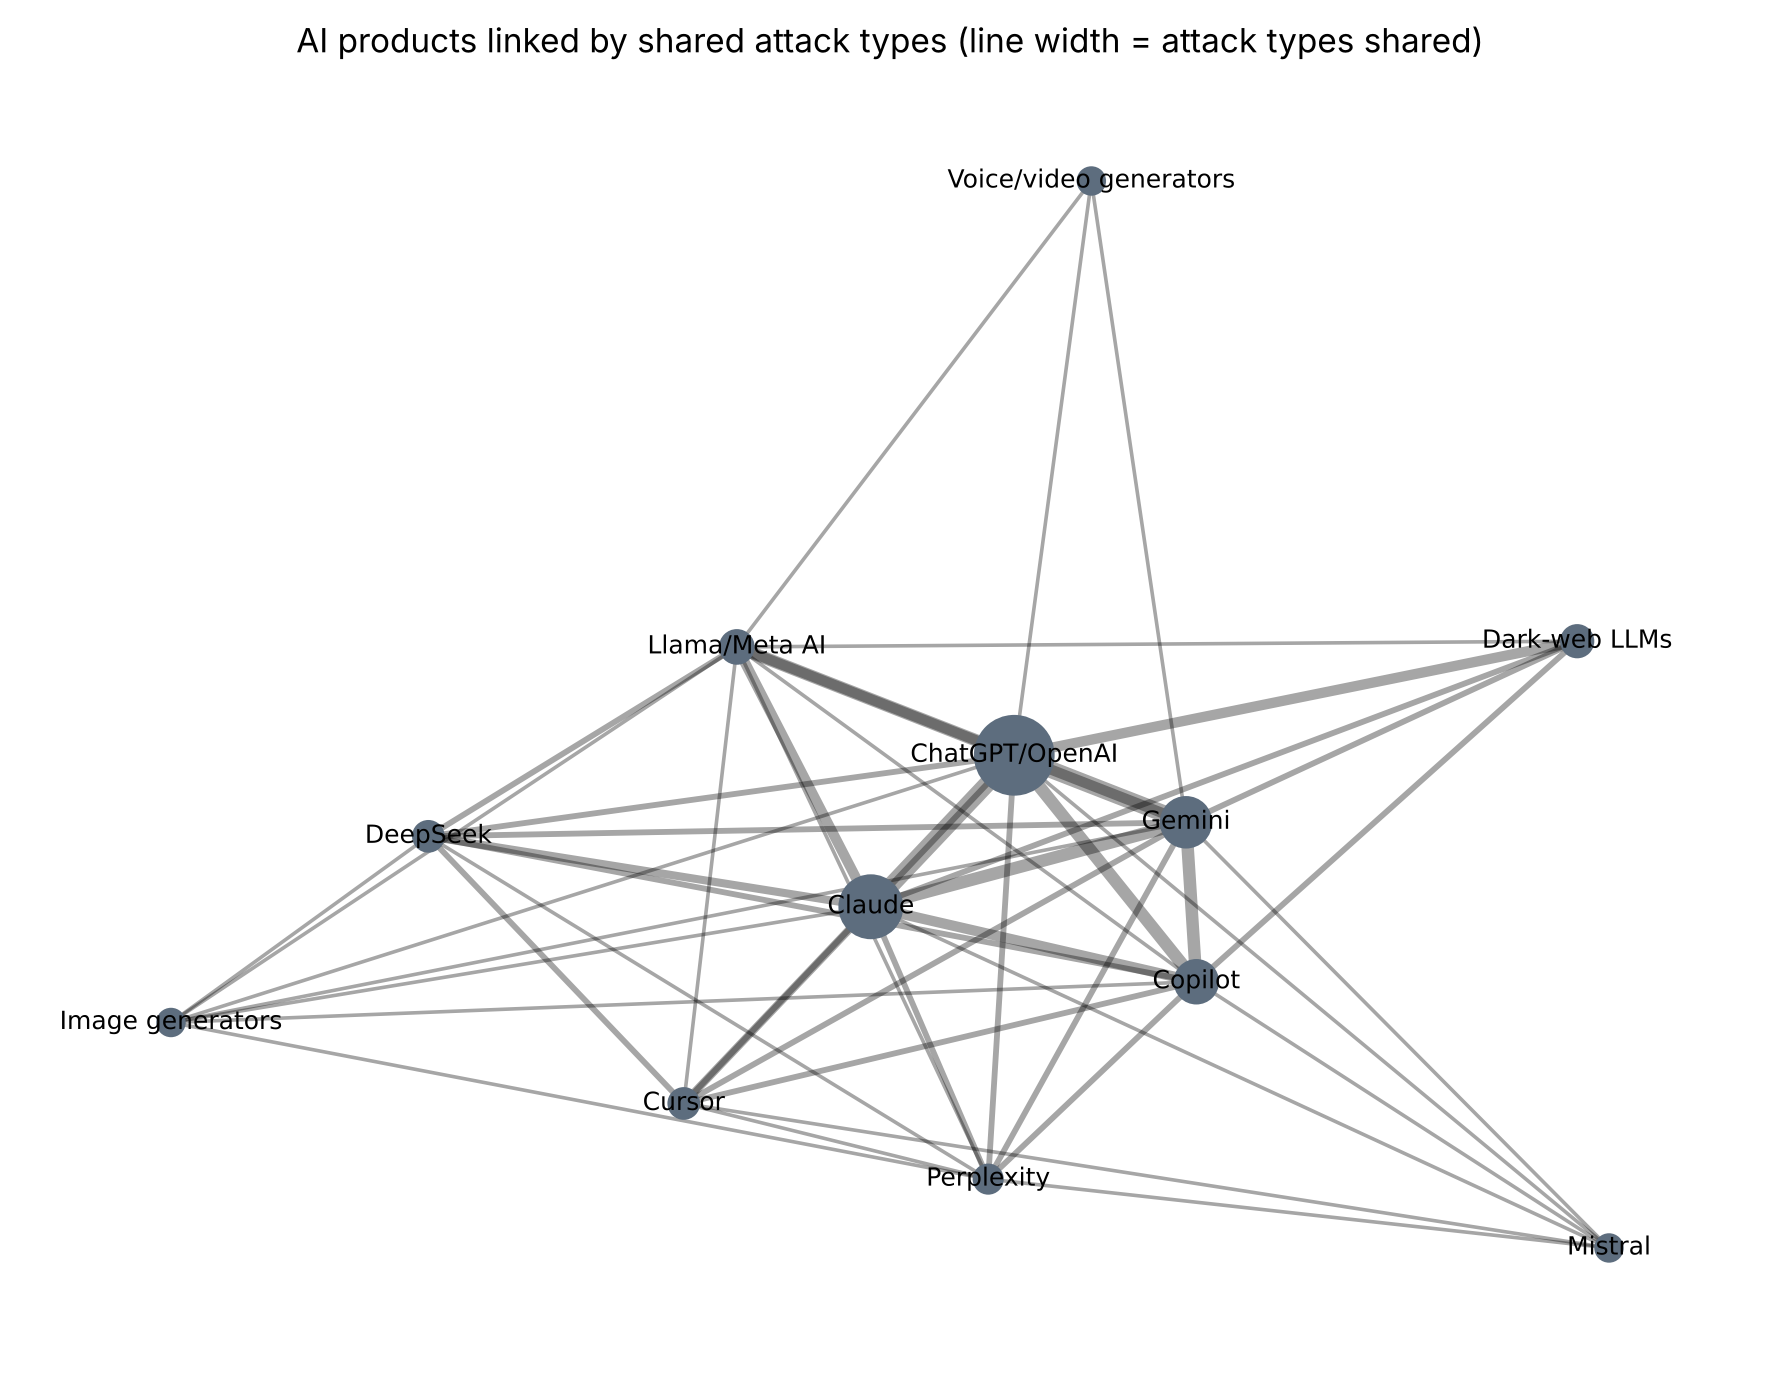

In [8]:
fig, ax = plt.subplots(figsize=(9, 7))
pos_p = nx.spring_layout(P, weight="weight", seed=42)
widths = [0.5 + 0.8 * w for _, _, w in P.edges(data="weight")]
nx.draw_networkx_edges(P, pos_p, width=widths, alpha=0.35, ax=ax)
nx.draw_networkx_nodes(P, pos_p, nodelist=list(P), node_color="#5d6d7e", ax=ax,
                       node_size=[80 + 12 * B.degree(n, weight="weight") for n in P])
nx.draw_networkx_labels(P, pos_p, font_size=9, ax=ax)
ax.set_title("AI products linked by shared attack types (line width = attack types shared)")
ax.axis("off")
plt.tight_layout()
plt.savefig("output/projection_ai_products.png", dpi=150, bbox_inches="tight")
plt.show()

The layout only places products so that heavily linked ones sit closer together. Distances on the page are not measurements.

## 6. MITRE ATLAS technique co-occurrence network

ATLAS is MITRE's catalogue of attack techniques against AI systems. Almost every incident here has ATLAS tags. I built a one-mode network where:

- **nodes** are ATLAS techniques, rolled up to the parent technique (so `AML.T0051.001` counts as `AML.T0051`). Without this, every sub-technique would be linked to its own parent, which tells us nothing.
- **edges** join two techniques tagged on the same incident, and the **weight** is the number of incidents they share.

### A tagging problem I found first

`AML.T0115.001` is tagged on 500 of the 843 incidents. In ATLAS 2026.09 it means *Publish Poisoned AI Artifacts: Models*, a supply-chain technique. That doesn't fit most of these incidents, which are deepfake scams. The dataset's v2.13.0 release notes say thousands of entries were re-mapped from old IDs to `AML.T0115.*`, and that no precision figure has been published for its mappings yet. So I build the network twice, with and without `AML.T0115`, and compare.

In [9]:
def parent(tid):
    return ".".join(tid.split(".")[:2])

def cooccurrence_graph(drop=()):
    G = nx.Graph()
    used = 0
    for tags in incidents.atlas_techniques:
        techs = sorted({parent(t) for t in tags.split(";") if t} - set(drop))
        if not techs:
            continue
        used += 1
        G.add_nodes_from(techs)
        for a, b in itertools.combinations(techs, 2):
            w = G[a][b]["weight"] + 1 if G.has_edge(a, b) else 1
            G.add_edge(a, b, weight=w)
    # betweenness treats weight as a distance, so stronger ties need shorter distances
    for _, _, d in G.edges(data=True):
        d["distance"] = 1 / d["weight"]
    G.graph["incidents_used"] = used
    return G

G_all = cooccurrence_graph()
G_clean = cooccurrence_graph(drop=["AML.T0115"])

for label, G in [("With AML.T0115", G_all), ("Without AML.T0115", G_clean)]:
    print(f"{label}: {G.graph['incidents_used']} incidents, {G.number_of_nodes()} techniques, "
          f"{G.number_of_edges()} edges, density {nx.density(G):.3f}, "
          f"components {nx.number_connected_components(G)}, isolates {len(list(nx.isolates(G)))}")

missing = [n for n in G_all if n not in atlas_name]
print("Techniques without a name in ATLAS 2026.09:", missing)
assert not missing

With AML.T0115: 821 incidents, 35 techniques, 279 edges, density 0.469, components 1, isolates 0
Without AML.T0115: 816 incidents, 34 techniques, 252 edges, density 0.449, components 1, isolates 0
Techniques without a name in ATLAS 2026.09: []


Both networks are dense: almost half of all possible technique pairs are linked. That's expected, because many incidents carry three or more tags. In a network this dense, plain degree doesn't separate nodes much, so I lean on weighted degree (strength), betweenness and eigenvector centrality.

- **Strength**: total incidents shared with other techniques.
- **Betweenness**: how often a technique sits on the shortest path between two others, using 1/weight as the distance.
- **Eigenvector**: high when a technique is tied strongly to other well-connected techniques.

In [10]:
def centrality_table(G):
    strength = dict(G.degree(weight="weight"))
    btw = nx.betweenness_centrality(G, weight="distance")
    eig = nx.eigenvector_centrality(G, weight="weight", max_iter=2000)
    t = pd.DataFrame({
        "technique": list(G),
        "name": [atlas_name[n] for n in G],
        "degree": [G.degree(n) for n in G],
        "strength": [strength[n] for n in G],
        "betweenness": [round(btw[n], 3) for n in G],
        "eigenvector": [round(eig[n], 3) for n in G],
    })
    return t.sort_values("strength", ascending=False).reset_index(drop=True)

cent_all = centrality_table(G_all)
cent_clean = centrality_table(G_clean)
print("With AML.T0115")
display(cent_all.head(8))
print("Without AML.T0115")
display(cent_clean.head(8))

With AML.T0115


,technique,name,degree,strength,betweenness,eigenvector
0,AML.T0048,External Harms,31,1186,0.379,0.577
1,AML.T0115,Publish Poisoned AI Artifacts,27,865,0.009,0.516
2,AML.T0057,LLM Data Leakage,26,780,0.073,0.329
3,AML.T0012,Valid Accounts,22,669,0.056,0.298
4,AML.T0050,Command and Scripting Interpreter,25,664,0.175,0.322
5,AML.T0053,AI Agent Tool Invocation,27,652,0.371,0.234
6,AML.T0010,AI Supply Chain Compromise,21,385,0.000,0.161
7,AML.T0051,LLM Prompt Injection,28,311,0.128,0.102


Without AML.T0115


,technique,name,degree,strength,betweenness,eigenvector
0,AML.T0057,LLM Data Leakage,25,714,0.074,0.476
1,AML.T0048,External Harms,30,696,0.361,0.450
2,AML.T0053,AI Agent Tool Invocation,26,610,0.381,0.350
3,AML.T0012,Valid Accounts,21,609,0.057,0.439
4,AML.T0050,Command and Scripting Interpreter,24,559,0.178,0.383
5,AML.T0010,AI Supply Chain Compromise,20,354,0.000,0.249
6,AML.T0051,LLM Prompt Injection,27,300,0.133,0.159
7,AML.T0066,Retrieval Content Crafting,25,170,0.011,0.071


In [11]:
compare = (cent_all[["technique", "name", "strength"]].head(6)
           .merge(cent_clean[["technique", "strength"]], on="technique", how="left",
                  suffixes=("_with", "_without")))
compare["rank_with"] = compare.index + 1
compare["rank_without"] = compare.technique.map(
    {t: i + 1 for i, t in enumerate(cent_clean.technique)})
compare

,technique,name,strength_with,strength_without,rank_with,rank_without
0,AML.T0048,External Harms,1186,696.0,1,2.0
1,AML.T0115,Publish Poisoned AI Artifacts,865,NaN,2,NaN
2,AML.T0057,LLM Data Leakage,780,714.0,3,1.0
3,AML.T0012,Valid Accounts,669,609.0,4,4.0
4,AML.T0050,Command and Scripting Interpreter,664,559.0,5,5.0
5,AML.T0053,AI Agent Tool Invocation,652,610.0,6,3.0


### Communities

I used Louvain community detection on the weighted network (seed 42 so it gives the same result every run). Louvain is a heuristic, so other seeds can split the smaller groups differently.

In [12]:
def community_table(G, seed=42):
    strength = dict(G.degree(weight="weight"))
    comms = nx.community.louvain_communities(G, weight="weight", seed=seed)
    rows = []
    for i, c in enumerate(sorted(comms, key=len, reverse=True), 1):
        top = sorted(c, key=strength.get, reverse=True)[:5]
        rows.append({"community": i, "size": len(c),
                     "strongest_techniques": "; ".join(atlas_name[n] for n in top)})
    return comms, pd.DataFrame(rows)

comms_all, ct_all = community_table(G_all)
comms_clean, ct_clean = community_table(G_clean)
print("With AML.T0115")
display(ct_all)
print("Without AML.T0115")
display(ct_clean)
print("Modularity without AML.T0115:",
      round(nx.community.modularity(G_clean, comms_clean, weight="weight"), 3))

With AML.T0115


,community,size,strongest_techniques
0,1,25,LLM Prompt Injection; Retrieval Content Crafti...
1,2,6,LLM Data Leakage; Valid Accounts; AI Agent Too...
2,3,4,External Harms; Publish Poisoned AI Artifacts;...


Without AML.T0115


,community,size,strongest_techniques
0,1,23,LLM Prompt Injection; Retrieval Content Crafti...
1,2,9,LLM Data Leakage; External Harms; AI Agent Too...
2,3,2,Cost Harvesting; Spamming AI System with Chaff...


Modularity without AML.T0115: 0.111


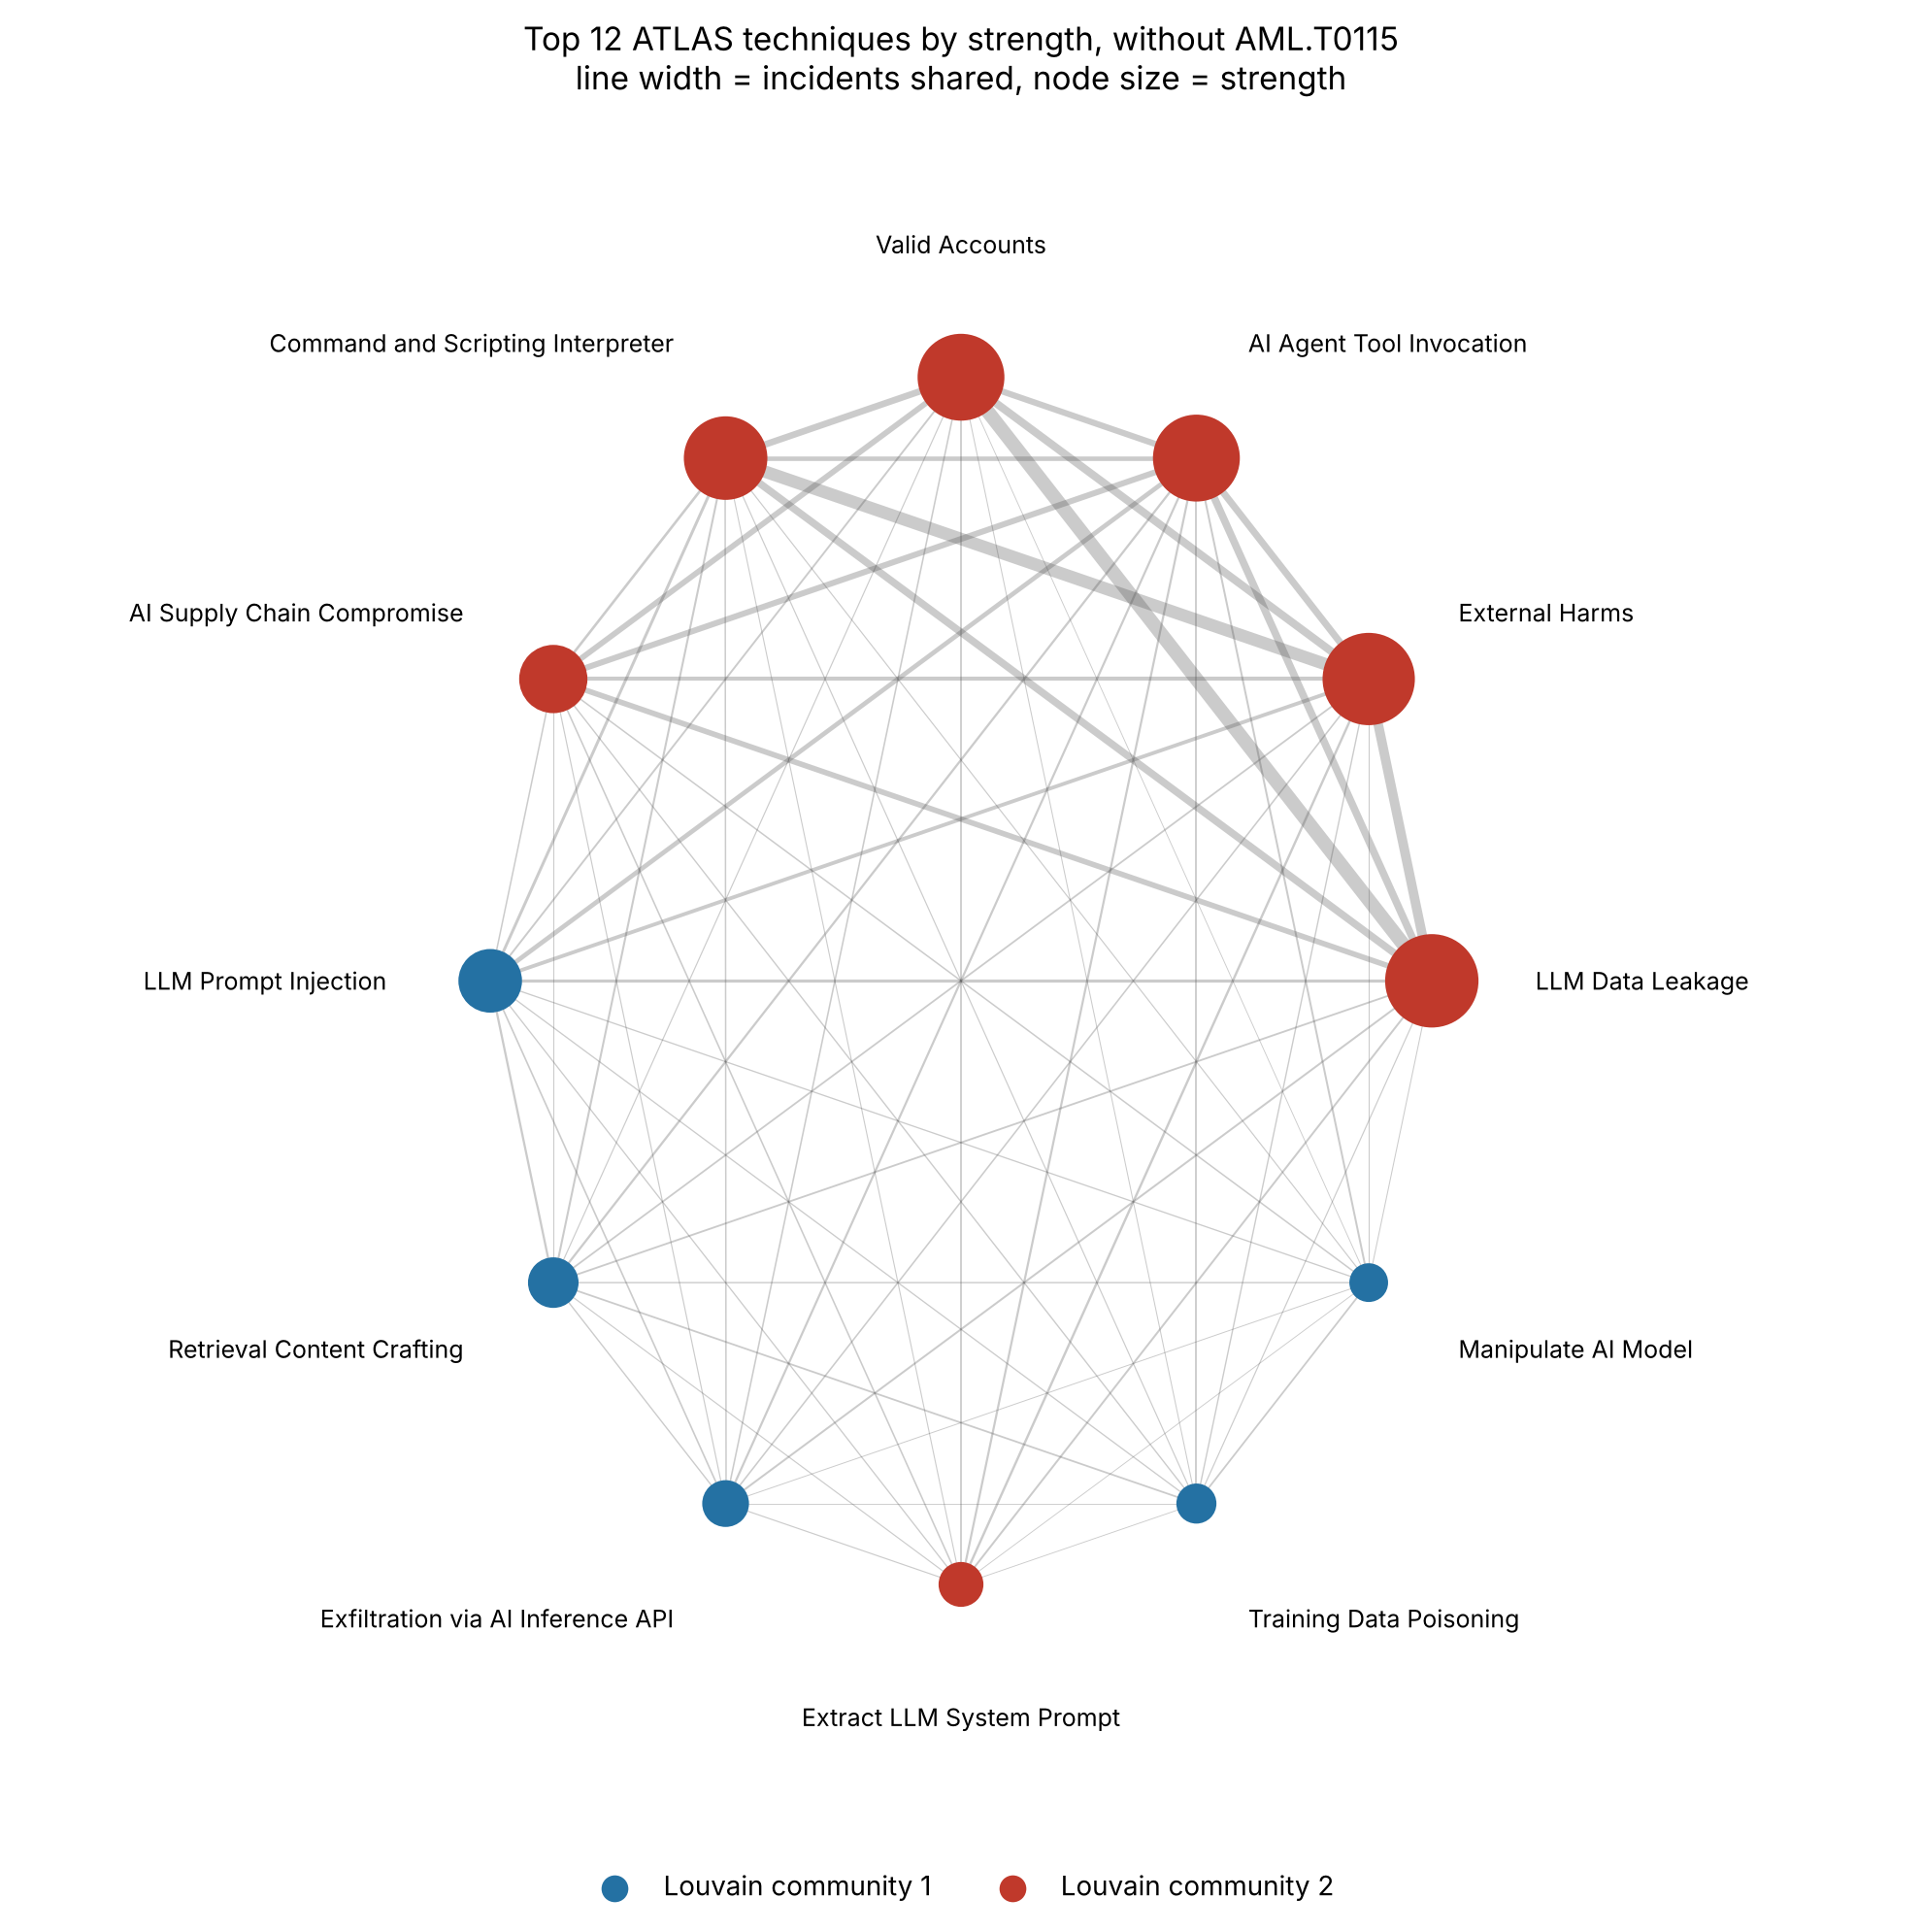

In [13]:
strength = dict(G_clean.degree(weight="weight"))
palette = ["#2471a3", "#c0392b", "#27ae60", "#8e44ad", "#d68910"]
community_of = {}
for i, c in enumerate(sorted(comms_clean, key=len, reverse=True)):
    for n in c:
        community_of[n] = i

top12 = list(cent_clean.technique.head(12))
H = G_clean.subgraph(top12)
pos_h = nx.circular_layout(top12)

fig, ax = plt.subplots(figsize=(10, 10))
nx.draw_networkx_edges(H, pos_h, ax=ax, alpha=0.3, edge_color="#555555",
                       width=[0.3 + H[u][v]["weight"] / 40 for u, v in H.edges()])
nx.draw_networkx_nodes(H, pos_h, nodelist=top12, ax=ax, node_color=[palette[community_of[n]] for n in top12],
                       node_size=[60 + 1.5 * strength[n] for n in top12])
for n, (x, y) in pos_h.items():
    ax.text(1.22 * x, 1.22 * y, atlas_name[n], ha="left" if x > 0.3 else ("right" if x < -0.3 else "center"),
            va="center", fontsize=9)
for i in sorted(set(community_of[n] for n in top12)):
    ax.scatter([], [], color=palette[i], s=80, label=f"Louvain community {i + 1}")
ax.legend(loc="lower center", ncol=3, frameon=False, bbox_to_anchor=(0.5, -0.04))
ax.set_title("Top 12 ATLAS techniques by strength, without AML.T0115\n"
             "line width = incidents shared, node size = strength")
ax.set_xlim(-2.0, 2.0); ax.set_ylim(-1.45, 1.45)
ax.axis("off")
plt.tight_layout()
plt.savefig("output/atlas_cooccurrence_top12.png", dpi=150, bbox_inches="tight")
plt.show()

The picture shows only the 12 techniques with the highest strength, with every edge between them. All the measures above were calculated on the full 34-technique network. Community numbers match the table above.

## 7. Findings

In [14]:
share = links.ai_role.value_counts()
print(f"Incident-to-product links: {len(links)}")
for role, n in share.items():
    print(f"  {role}: {n} ({n / len(links):.0%})")
print()
print("Top technique by strength, with AML.T0115:   ", cent_all.name[0], cent_all.strength[0])
print("Top technique by strength, without AML.T0115:", cent_clean.name[0], cent_clean.strength[0])
ext = cent_clean.loc[cent_clean.technique == "AML.T0048", "strength"].item()
print("External Harms strength drops from", cent_all.strength[0], "to", ext)

Incident-to-product links: 147
  AI product attacked: 102 (69%)
  AI used as weapon: 25 (17%)
  unclear: 20 (14%)

Top technique by strength, with AML.T0115:    External Harms 1186
Top technique by strength, without AML.T0115: LLM Data Leakage 714
External Harms strength drops from 1186 to 696


1. **AI products are mostly the target, not the weapon.** Where an incident names an AI product, about 7 in 10 links are attacks *on* that product (prompt injection, data leakage, jailbreaks). Fewer than 1 in 5 are AI used as a weapon. ChatGPT/OpenAI has the most links overall and also the most weapon links.
2. **The most-named products share the most attack types.** In the projection, ChatGPT/OpenAI shares 7 attack types each with Gemini and Claude. That reflects how widely these products are used and reported on, so it is exposure, not a ranking of how secure each one is. The projection is also very dense (0.742), so almost every product is linked to almost every other one.
3. **One questionable tag changes the ATLAS results.** With `AML.T0115` included, *External Harms* is the clear hub. Without it, *LLM Data Leakage* has the highest strength. So the "most central technique" depends on a tag that probably shouldn't be there.
4. **The communities are weak.** Modularity is only 0.111 without `AML.T0115`, so the network does not split cleanly into separate groups. I treat the communities as a rough grouping, not a finding.
5. **The victim side is missing.** The data can't link these attacks to named companies, Fortune 500 or otherwise.

## 8. What this does not show

- Centrality here describes how **tags** cluster in public reporting, not how real attackers operate. The ATLAS tags were assigned by the dataset's automated mapper, and the dataset has not published a precision figure for them.
- The AI-role label comes from the attack type, not from reading each incident, so some links will be in the wrong role.
- Products named more often in the news will look more central. A high degree is not evidence that a product is less secure.
- Only 134 of the 843 incidents name an AI product, so the two-mode network covers a minority of the data.